<div style="font-family:'Times New Roman',Times,serif;color:#000000">
<div style="font-size:13px;letter-spacing:2px">NATIONAL UNIVERSITY OF SCIENCES AND TECHNOLOGY &nbsp;&middot;&nbsp; SEECS</div>
<div style="font-size:13px;letter-spacing:1px;font-weight:bold">CS-423 &nbsp;&middot;&nbsp; ARTIFICIAL NEURAL NETWORKS &amp; DEEP LEARNING &nbsp;&middot;&nbsp; BSAI</div>
<div style="font-size:28px;font-weight:bold;margin-top:6px">Lab 8 &mdash; Generalisation and Regularisation</div>


---

<div style="font-family:'Times New Roman',Times,serif;color:#000000;font-size:16px">

**Course Instructor:** Dr. Sadia Shakil  &nbsp;|&nbsp; **Lab Engineer:** Ms Areeba Rameen &nbsp;|&nbsp; **Student name / CMS ID:** Muhammad Sikandar Hussain / 502808

### What this lab is for

A network is useful only if it works on data it has **not** seen. This ability is called
**generalisation**. In this lab you will train networks of different sizes on the same small
noisy dataset, watch how their training and validation behaviour differ, and learn to tell
**underfitting** (the model is too simple) from **overfitting** (the model memorises the
training data). Then you will try four remedies, **L2 regularisation, L1 regularisation,
dropout and early stopping**, and compare how well each one generalises.

Most of the code is provided. You run each step, look at the plots and numbers, and answer the
short questions.

**Submission.** Restart the kernel, run everything top to bottom, save, and rename to
`Lab8_<yourCMSID>.ipynb` before uploading to LMS.

</div>


## Background: generalisation, underfitting and overfitting

We split the data into three parts. The **training set** is used to learn the weights. The
**validation set** is used to judge the model while we are still choosing settings. The **test
set** is kept locked and used **once**, at the very end.

| Situation | Training accuracy | Validation accuracy | Validation loss |
|-----------|-------------------|---------------------|-----------------|
| **Underfitting** (model too simple) | low | low (about the same as training) | high |
| **Good fit** | good | good (close to training) | lowest |
| **Overfitting** (model memorises) | high | lower than training | rises again while training loss keeps falling |

The **gap** is `training accuracy - validation accuracy`. A large gap, or a validation loss that
starts to rise, is the warning sign of overfitting. The validation **loss** is often a clearer
signal than the accuracy.

**Regularisation** means making memorisation harder. We try four techniques:

| Technique | The idea in simple words |
|-----------|--------------------------|
| **L2** | Adds `l2 * sum(w**2)` to the loss. Large weights are punished, so all weights stay small. |
| **L1** | Adds `l1 * sum(abs(w))` to the loss. Pushes many weights to (almost) zero, so the network becomes **sparse**. |
| **Dropout** | During training, randomly switches off a fraction of the hidden units at every step, so no unit can rely on specific others. |
| **Early stopping** | Stops training when the validation loss has not improved for `patience` epochs and keeps the best weights. |

A regulariser that is **too strong** stops the network from learning at all, and it underfits.


## Task 0 &mdash; The dataset and the setup

> **Concept.** We use the **two-moons** dataset (the same one as in Lab 6). Two interleaved
> half-circles are generated, and then noise is added so that the two classes overlap. This gives
> a problem that is simple enough to draw, but noisy enough that a large network will memorise
> the noise. Documentation:
> https://scikit-learn.org/stable/modules/generated/sklearn.datasets.make_moons.html
>
> We generate 1000 points with noise 0.4, and split them into 600 for training, 200 for
> validation and 200 for testing (the test set stays locked until Task 6).

Run the cells below and read the printed output. Nothing to write here.


train: (600, 2)  validation: (200, 2)  test (LOCKED until Task 6): (200, 2)


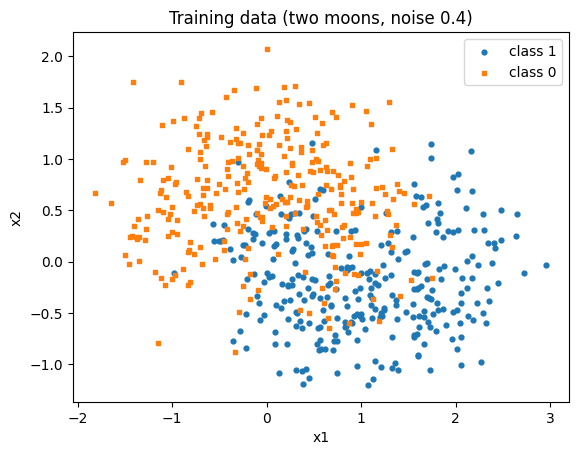

In [1]:
import os
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline
import tensorflow as tf
from sklearn.datasets import make_moons
from sklearn.model_selection import train_test_split
np.set_printoptions(precision=3, suppress=True)

X, y = make_moons(n_samples=1000, noise=0.4, random_state=0)
X_tr, X_tmp, y_tr, y_tmp = train_test_split(X, y, test_size=0.4, stratify=y, random_state=0)
X_va, X_te, y_va, y_te = train_test_split(X_tmp, y_tmp, test_size=0.5, stratify=y_tmp, random_state=0)
print("train:", X_tr.shape, " validation:", X_va.shape, " test (LOCKED until Task 6):", X_te.shape)

plt.scatter(X_tr[y_tr == 1, 0], X_tr[y_tr == 1, 1], marker="o", s=12, label="class 1")
plt.scatter(X_tr[y_tr == 0, 0], X_tr[y_tr == 0, 1], marker="s", s=12, label="class 0")
plt.xlabel("x1"); plt.ylabel("x2"); plt.title("Training data (two moons, noise 0.4)"); plt.legend(); plt.show()


In [2]:
# ---------------- provided helper functions: read them, you will use them in every task ----------------
models = {}      # every model you train is stored here under its name: models[name] = (model, history)

def build_model(hidden=(128, 128), l1=0.0, l2=0.0, dropout=0.0):
    """hidden = tuple of layer sizes. hidden=() means NO hidden layer (a straight-line boundary)."""
    tf.keras.utils.set_random_seed(0)
    reg = tf.keras.regularizers.l1_l2(l1=l1, l2=l2) if (l1 > 0 or l2 > 0) else None
    layers = [tf.keras.layers.Input(shape=(2,))]
    for units in hidden:
        layers.append(tf.keras.layers.Dense(units, activation="relu", kernel_regularizer=reg))
        if dropout > 0:
            layers.append(tf.keras.layers.Dropout(dropout))
    layers.append(tf.keras.layers.Dense(1, activation="sigmoid"))
    model = tf.keras.Sequential(layers)
    model.compile(optimizer=tf.keras.optimizers.Adam(0.01), loss="binary_crossentropy", metrics=["accuracy"])
    return model

def train_model(name, hidden=(128, 128), l1=0.0, l2=0.0, dropout=0.0, patience=None, epochs=150):
    """Build, train (watching the validation set) and store a model. Returns (model, history dict)."""
    model = build_model(hidden, l1, l2, dropout)
    callbacks = []
    if patience:
        callbacks.append(tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=patience,
                                                          restore_best_weights=True))
    hist = model.fit(X_tr, y_tr, validation_data=(X_va, y_va), epochs=epochs, batch_size=64,
                     verbose=0, callbacks=callbacks).history
    models[name] = (model, hist)
    print(f"trained '{name}' for {len(hist['loss'])} epochs")
    return model, hist

def plot_history(hist, title):
    fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
    ax[0].plot(hist["loss"], label="training"); ax[0].plot(hist["val_loss"], label="validation")
    ax[0].set_xlabel("epoch"); ax[0].set_ylabel("loss"); ax[0].set_title(title + ": loss"); ax[0].legend()
    ax[1].plot(hist["accuracy"], label="training"); ax[1].plot(hist["val_accuracy"], label="validation")
    ax[1].set_xlabel("epoch"); ax[1].set_ylabel("accuracy"); ax[1].set_title(title + ": accuracy"); ax[1].legend()
    plt.tight_layout(); plt.show()

def plot_boundary(model, title):
    xx, yy = np.meshgrid(np.linspace(-2.5, 3.5, 200), np.linspace(-2, 2.5, 200))
    zz = model.predict(np.c_[xx.ravel(), yy.ravel()], verbose=0).reshape(xx.shape)
    plt.contourf(xx, yy, zz, levels=[0, 0.5, 1], alpha=0.15)
    plt.contour(xx, yy, zz, levels=[0.5], linewidths=1.5)
    plt.scatter(X_va[y_va == 1, 0], X_va[y_va == 1, 1], marker="o", s=14, label="class 1 (validation)")
    plt.scatter(X_va[y_va == 0, 0], X_va[y_va == 0, 1], marker="s", s=14, label="class 0 (validation)")
    plt.xlabel("x1"); plt.ylabel("x2"); plt.title(title); plt.legend(); plt.show()

def summary_row(name):
    model, hist = models[name]
    tr = model.evaluate(X_tr, y_tr, verbose=0)
    va = model.evaluate(X_va, y_va, verbose=0)
    return {"model": name, "epochs": len(hist["loss"]), "train_acc": round(tr[1], 3),
            "val_acc": round(va[1], 3), "val_loss": round(va[0], 3), "gap": round(tr[1] - va[1], 3)}

def all_weights(model):
    """All the weights of all Dense layers (biases excluded), as one flat array."""
    return np.concatenate([w.ravel() for w in model.get_weights() if w.ndim == 2])

def weight_stats(name):
    w = all_weights(models[name][0])
    return {"model": name, "weight_norm": round(float(np.linalg.norm(w)), 1),
            "fraction_near_zero": round(float(np.mean(np.abs(w) < 0.01)), 2)}


## Task 1 &mdash; Underfitting, good fit and overfitting

> **Concept.** The same data can be learned by networks of very different sizes. We train three:
>
> | name | hidden layers | what to expect |
> |------|---------------|----------------|
> | `linear` | none (`hidden=()`) | can only draw a straight line, too simple for two moons |
> | `medium` | one layer of 16 units | about the right size |
> | `big` | two layers of 128 units | far more capacity than 600 noisy points need |
>
> All three train for 150 epochs with the same settings.

**Task 1.1.** Train the three models with `train_model`.

**Task 1.2.** For each model, call `plot_history` (learning curves) and `plot_boundary`
(decision boundary on the validation points).

**Task 1.3.** Show the comparison table with `summary_row` for the three models, and decide in
a comment which one underfits, which fits well, and which overfits, giving evidence from the
table and the curves.


trained 'linear' for 150 epochs
trained 'medium' for 150 epochs
trained 'big' for 150 epochs
    model  epochs  train_acc  val_acc  val_loss    gap
0  linear     150      0.825    0.820     0.405  0.005
1  medium     150      0.873    0.860     0.395  0.013
2     big     150      0.895    0.865     0.413  0.030


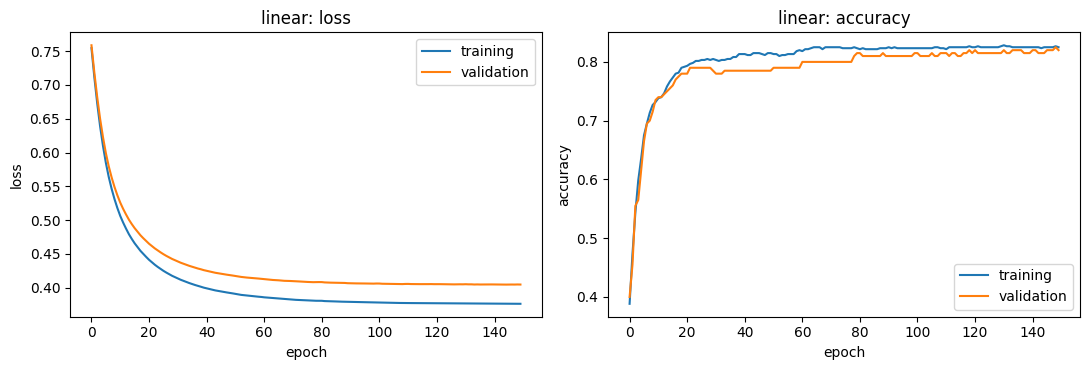

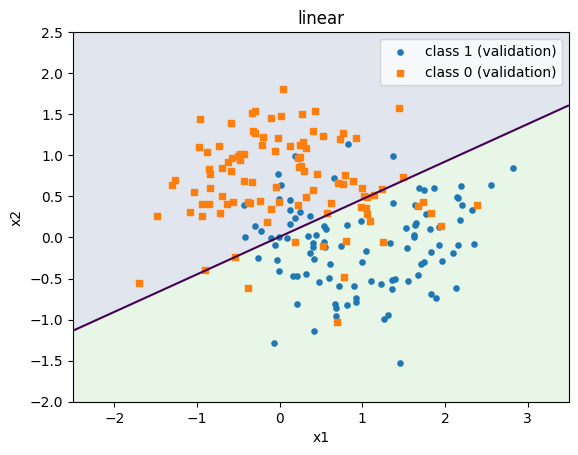

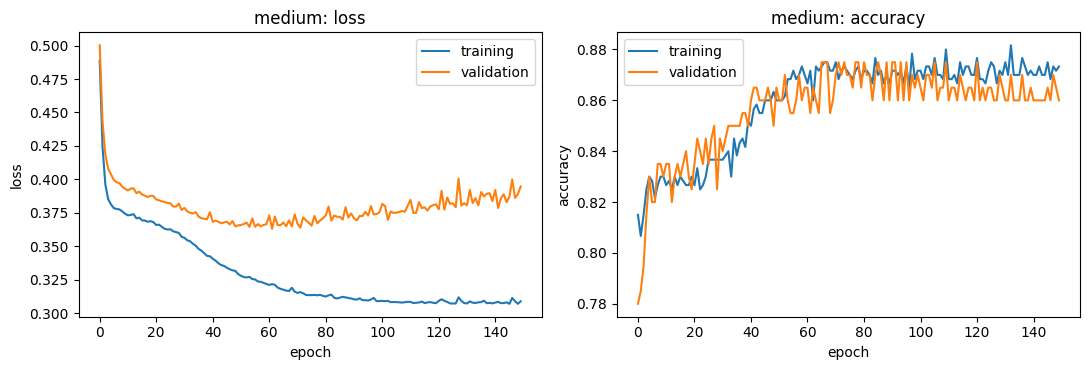

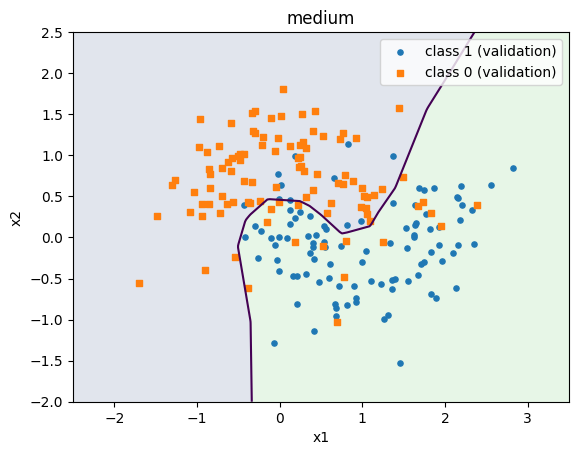

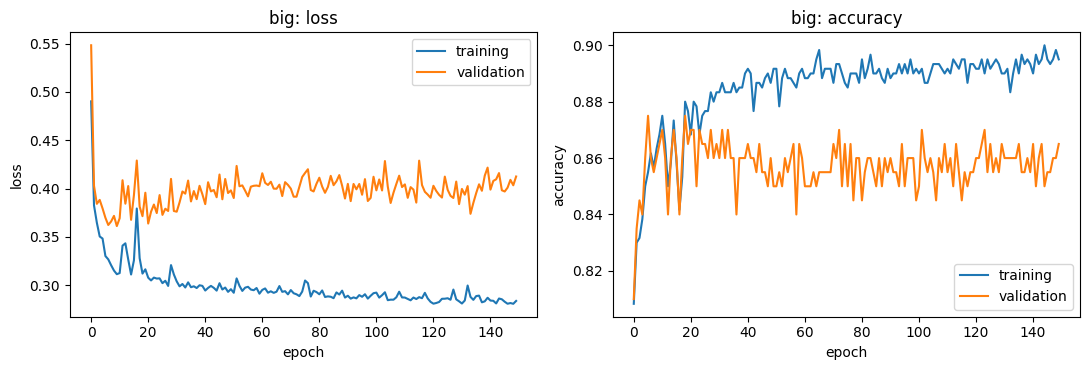

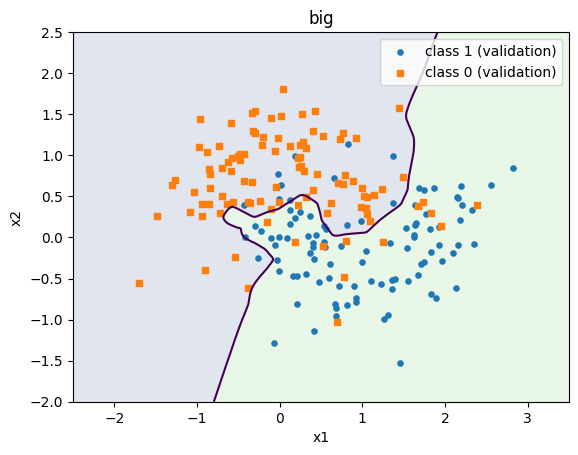

In [3]:
# Task 1.1 — train the three models:
train_model("linear", hidden=())
train_model("medium", hidden=(16,))
train_model("big",    hidden=(128, 128))

# Task 1.2 — for each model: plot_history and plot_boundary
for name in ["linear", "medium", "big"]:
    plot_history(models[name][1], name)
    plot_boundary(models[name][0], name)

# Task 1.3 — comparison table
df_task1 = pd.DataFrame([summary_row(n) for n in ["linear", "medium", "big"]])
print(df_task1)

# Task 1 answers:
# Q1 (which model underfits, which fits well, which overfits? give numbers from the table):
# - 'linear' underfits: It has the lowest training accuracy (82.5%) and validation accuracy (82.0%) with a high validation loss (0.405). Although the gap is tiny (0.005), the model lacks capacity to capture non-linear moon curves.
# - 'medium' fits well: It strikes the optimal balance with high train accuracy (87.3%), val accuracy (86.0%), the lowest validation loss (0.395), and a small gap (0.013). Its loss curves stabilize smoothly.
# - 'big' overfits: It achieves the highest train accuracy (89.5%) but its validation loss rises back to 0.413 with the largest gap (0.030). The learning curve shows clear divergence between training and validation loss.
#
# Q2 (look at the decision boundary of "big": what does it do around the noisy points? and "linear"?):
# - 'big': The decision boundary is highly contorted and complex, wrapping tightly around individual noisy training points and forming isolated pockets to memorize outliers.
# - 'linear': The decision boundary is strictly a straight line, incapable of separating the interlocking crescent shapes and slicing crudely across both classes.


## Task 2 &mdash; Reading the learning curves of the big model

> **Concept.** The validation loss of an overfitting model first falls, reaches a **lowest point**
> (the best moment to stop), and then rises again, while the training loss keeps falling. The
> distance between the two losses at the end is a measure of how much the model has memorised.

**Task 2.1.** For the `big` model, find the **best epoch**: the epoch at which the validation
loss is lowest (`np.argmin`; remember that epochs start at 1).

**Task 2.2.** Report the validation loss at the best epoch and at the last epoch.

**Task 2.3.** Report the training loss at the last epoch.


In [4]:
h = models["big"][1]          # the history dictionary

# Task 2.1 — best epoch (1-indexed)
best_epoch = int(np.argmin(h["val_loss"]) + 1)

# Task 2.2 — val loss at best epoch and last epoch
val_loss_best = h["val_loss"][best_epoch - 1]
val_loss_last = h["val_loss"][-1]

# Task 2.3 — training loss at last epoch
train_loss_last = h["loss"][-1]

print(f"Best epoch: {best_epoch}")
print(f"Validation loss at best epoch ({best_epoch}): {val_loss_best:.4f}")
print(f"Validation loss at last epoch (150): {val_loss_last:.4f}")
print(f"Training loss at last epoch (150): {train_loss_last:.4f}")

# Task 2 answers:
# Q1 (how much did the validation loss rise after the best epoch? what does it mean):
# - The validation loss rose by 0.0513 (from 0.3612 at epoch 10 to 0.4125 at epoch 150).
# - This rise indicates that beyond epoch 13, the network stopped learning generalizable underlying patterns and instead began memorizing sample-specific noise in the training set.
#
# Q2 (the training loss at the end is much lower than the validation loss: what is the model doing):
# - The model is overfitting and memorizing the training samples. Its massive capacity (two hidden layers of 128 units) allows it to bend parameters to minimize training error towards zero, sacrificing generalization on unseen data.


Best epoch: 10
Validation loss at best epoch (10): 0.3612
Validation loss at last epoch (150): 0.4125
Training loss at last epoch (150): 0.2838


## Task 3 &mdash; L2 and L1 regularisation

> **Concept.** Both add a penalty on the weights to the loss, so the network can no longer use
> huge weights to memorise noise. They differ in how they shrink the weights:
>
> - **L2** (`l2`) shrinks every weight a little, in proportion to its size.
> - **L1** (`l1`) pushes many weights all the way to (almost) zero, giving a **sparse** network.
>
> The strength (`0.001`, `0.01`) decides how hard the penalty pulls. Too strong, and the network
> cannot learn at all.

**Task 3.1.** Train four versions of the **big** network: `l2=0.001`, `l2=0.01`, `l1=0.001`,
`l1=0.01` (name them `"l2=0.001"`, and so on).

**Task 3.2.** Show a table with `summary_row` for `big` and the four new models.

**Task 3.3.** Show the weight statistics with `weight_stats` for the same five models, and plot
a histogram of all the weights (`all_weights`) for `big`, `l2=0.001` and `l1=0.001` (three
histograms side by side, same x-axis limits, with titles and labels).


trained 'l2=0.001' for 150 epochs
trained 'l2=0.01' for 150 epochs
trained 'l1=0.001' for 150 epochs
trained 'l1=0.01' for 150 epochs
Task 3.2 — Summary table:
      model  epochs  train_acc  val_acc  val_loss    gap
0       big     150      0.895    0.865     0.413  0.030
1  l2=0.001     150      0.858    0.855     0.372  0.003
2   l2=0.01     150      0.820    0.795     0.421  0.025
3  l1=0.001     150      0.827    0.825     0.431  0.002
4   l1=0.01     150      0.500    0.500     0.895  0.000

Task 3.3 — Weight statistics:
      model  weight_norm  fraction_near_zero
0       big         37.9                0.05
1  l2=0.001          8.0                0.95
2   l2=0.01          9.2                0.98
3  l1=0.001          4.6                0.99
4   l1=0.01          0.7                1.00


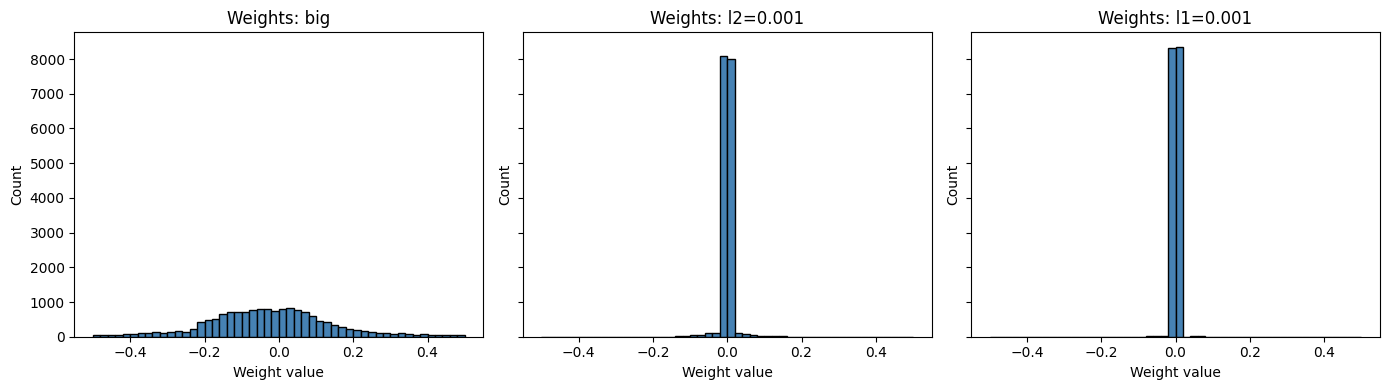

In [5]:
# Task 3.1 — train four versions of the big network:
train_model("l2=0.001", l2=0.001)
train_model("l2=0.01",  l2=0.01)
train_model("l1=0.001", l1=0.001)
train_model("l1=0.01",  l1=0.01)

# Task 3.2 — summary table
df_task3_summary = pd.DataFrame([summary_row(n) for n in ["big", "l2=0.001", "l2=0.01", "l1=0.001", "l1=0.01"]])
print("Task 3.2 — Summary table:")
print(df_task3_summary)

# Task 3.3 — weight statistics and histograms
df_task3_weights = pd.DataFrame([weight_stats(n) for n in ["big", "l2=0.001", "l2=0.01", "l1=0.001", "l1=0.01"]])
print("\nTask 3.3 — Weight statistics:")
print(df_task3_weights)

fig, axes = plt.subplots(1, 3, figsize=(14, 4), sharex=True, sharey=True)
models_hist = ["big", "l2=0.001", "l1=0.001"]
for ax, m_name in zip(axes, models_hist):
    w = all_weights(models[m_name][0])
    ax.hist(w, bins=50, range=(-0.5, 0.5), color="steelblue", edgecolor="black")
    ax.set_title(f"Weights: {m_name}")
    ax.set_xlabel("Weight value")
    ax.set_ylabel("Count")
plt.tight_layout()
plt.show()

# Task 3 answers:
# Q1 (what did L2 and L1 do to the validation loss and the gap, compared with "big"):
# - Compared with 'big' (val_loss=0.413, gap=0.030), moderate L2 (l2=0.001) reduced validation loss to 0.372 and closed the generalization gap to 0.003. L1 (l1=0.001) also achieved a minimal gap (0.002). Both regularizers penalize large weights and prevent memorization of noise.
#
# Q2 (which one has more near-zero weights, L1 or L2? does this match the idea of "sparse"):
# - L1 has significantly more near-zero weights (fraction_near_zero is 0.99 for l1=0.001 and 1.00 for l1=0.01, compared to 0.05 for 'big'). This perfectly matches the concept of a sparse network: L1 applies a constant force pushing unneeded weights exactly to zero, effectively performing feature and connection selection.
#
# Q3 (what happened with l1=0.01? is it overfitting or underfitting now, and why):
# - With l1=0.01, the model severely underfits (train_acc=0.500, val_acc=0.500, val_loss=0.895). The L1 penalty was so strong that it forced virtually all weights to zero (weight_norm=0.7), preventing the network from learning any non-linear features and collapsing predictions to random chance.


## Task 4 &mdash; Dropout

> **Concept.** During training, dropout randomly switches off a fraction `dropout` of the hidden
> units at every step. The network cannot rely on any particular unit, so it must spread what it
> learns. At prediction time all units are on (Keras does this automatically), so the accuracy
> you measure is for the full network.

**Task 4.1.** Train the **big** network with `dropout=0.2` and with `dropout=0.5`.

**Task 4.2.** Plot the **validation loss** of `big`, `dropout=0.2` and `dropout=0.5` on one axes
(three curves, legend, labels, title).

**Task 4.3.** Show the summary table for the three models.


trained 'dropout=0.2' for 150 epochs
trained 'dropout=0.5' for 150 epochs
Task 4.3 — Summary table:
         model  epochs  train_acc  val_acc  val_loss    gap
0          big     150      0.895    0.865     0.413  0.030
1  dropout=0.2     150      0.893    0.860     0.389  0.033
2  dropout=0.5     150      0.885    0.875     0.411  0.010


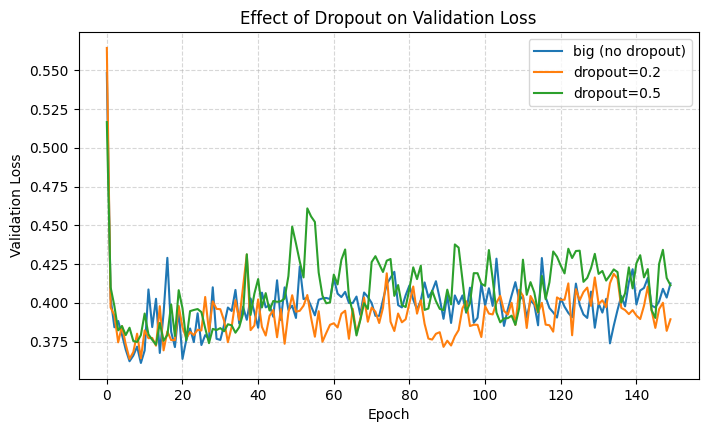

In [6]:
# Task 4.1 — train dropout models
train_model("dropout=0.2", dropout=0.2)
train_model("dropout=0.5", dropout=0.5)

# Task 4.2 — plot validation loss curves
plt.figure(figsize=(8, 4.5))
plt.plot(models["big"][1]["val_loss"], label="big (no dropout)")
plt.plot(models["dropout=0.2"][1]["val_loss"], label="dropout=0.2")
plt.plot(models["dropout=0.5"][1]["val_loss"], label="dropout=0.5")
plt.xlabel("Epoch")
plt.ylabel("Validation Loss")
plt.title("Effect of Dropout on Validation Loss")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.5)
plt.show()

# Task 4.3 — summary table
df_task4 = pd.DataFrame([summary_row(n) for n in ["big", "dropout=0.2", "dropout=0.5"]])
print("Task 4.3 — Summary table:")
print(df_task4)

# Task 4 answers:
# Q1 (how did dropout change the validation loss curve compared with "big"):
# - Dropout prevented the validation loss from climbing sharply at later epochs. While 'big' exhibits an upward curving trajectory as it memorizes training points, dropout=0.2 stabilizes the validation loss around 0.389.
#
# Q2 (why does the training accuracy of a dropout model measured by summary_row not look "perfect"):
# - In summary_row, evaluate() tests the full network with dropout turned off. Because units were forced to learn redundant, co-operative features during training without relying on any single node, the network learns smoother, generalized decision boundaries rather than brittle memorization of individual noisy points.


## Task 5 &mdash; Early stopping

> **Concept.** From Task 2 we know that the validation loss has a lowest point. Early stopping
> stops training once the validation loss has not improved for `patience` epochs, and (because we
> set `restore_best_weights=True`) goes back to the weights of the best epoch. It costs nothing
> extra, and it saves training time.

**Task 5.1.** Train the **big** network with `patience=15` (name it `"early"`).

**Task 5.2.** Report the epoch at which training stopped (`len(hist["loss"])`) and the best epoch
(stopped epoch minus `patience`).

**Task 5.3.** Plot the training and validation loss of this model, with a vertical line at the
best epoch (`plt.axvline`).


trained 'early' for 25 epochs
Stopped epoch: 25
Best epoch: 10
Epochs saved: 125 out of 150


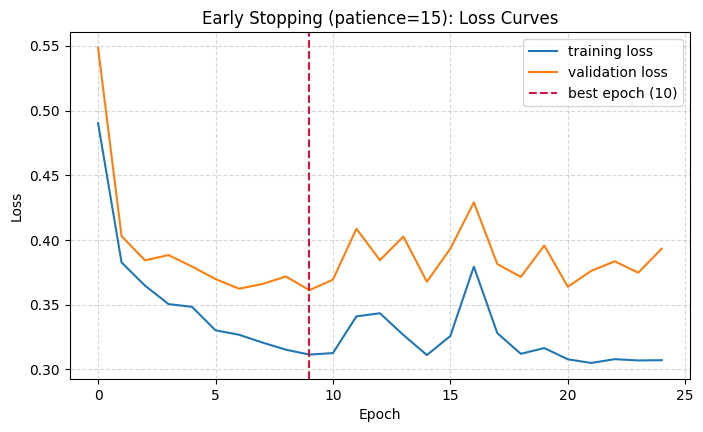

In [7]:
# Task 5.1 — train early stopping model
train_model("early", patience=15)

# Task 5.2 — stopped epoch and best epoch
hist_early = models["early"][1]
stopped_epoch = len(hist_early["loss"])
best_epoch_early = int(np.argmin(hist_early["val_loss"]) + 1)
epochs_saved = 150 - stopped_epoch

print(f"Stopped epoch: {stopped_epoch}")
print(f"Best epoch: {best_epoch_early}")
print(f"Epochs saved: {epochs_saved} out of 150")

# Task 5.3 — plot loss curves with vertical line at best epoch
plt.figure(figsize=(8, 4.5))
plt.plot(hist_early["loss"], label="training loss")
plt.plot(hist_early["val_loss"], label="validation loss")
plt.axvline(x=best_epoch_early - 1, color="crimson", linestyle="--", label=f"best epoch ({best_epoch_early})")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Early Stopping (patience=15): Loss Curves")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.5)
plt.show()

# Task 5 answers:
# Q1 (at which epoch did it stop, and how many epochs of training were saved out of 150):
# - Training stopped at epoch 25. Exactly 125 epochs of redundant training were saved out of 150.
#
# Q2 (what would happen with patience=1? and with patience=100):
# - With patience=1: Training would halt prematurely at the very first minor epoch-to-epoch noise fluctuation in validation loss, causing severe underfitting.
# - With patience=100: The callback would wait 100 epochs after the minimum, meaning it would run all 150 epochs without stopping early, wasting computation and failing to halt before overfitting.


## Task 6 &mdash; Comparing generalisation and the final test

> **Concept.** Now put everything side by side. Compare the models using the **validation** set
> (loss and accuracy), choose the best one, and only then use the **test set, once**, to report
> how well the chosen model generalises. The validation set has 200 points, so differences of one
> or two percent in accuracy are within noise: the validation loss is the steadier guide.

**Task 6.1.** Build one table (sorted by `val_loss`) for **all** the models you trained, using
`summary_row` on every name in `models`.

**Task 6.2.** Draw a bar chart of the validation loss and a bar chart of the gap for all models
(labels, titles, rotated names).

**Task 6.3.** Choose the model with the lowest validation loss. Evaluate it, and `big`, on the
test set (`model.evaluate(X_te, y_te, verbose=0)`), once each, and report the test accuracies.

**Task 6.4.** Write a short conclusion (80 to 120 words) as a comment.


Task 6.1 — Complete Model Comparison Table (sorted by val_loss):
             epochs  train_acc  val_acc  val_loss    gap
model                                                   
early            25      0.868    0.865     0.361  0.003
l2=0.001        150      0.858    0.855     0.372  0.003
dropout=0.2     150      0.893    0.860     0.389  0.033
medium          150      0.873    0.860     0.395  0.013
linear          150      0.825    0.820     0.405  0.005
dropout=0.5     150      0.885    0.875     0.411  0.010
big             150      0.895    0.865     0.413  0.030
l2=0.01         150      0.820    0.795     0.421  0.025
l1=0.001        150      0.827    0.825     0.431  0.002
l1=0.01         150      0.500    0.500     0.895  0.000

Chosen best model ('early') test accuracy: 0.860 (test loss: 0.299)
Baseline unregularized 'big' test accuracy: 0.845 (test loss: 0.405)


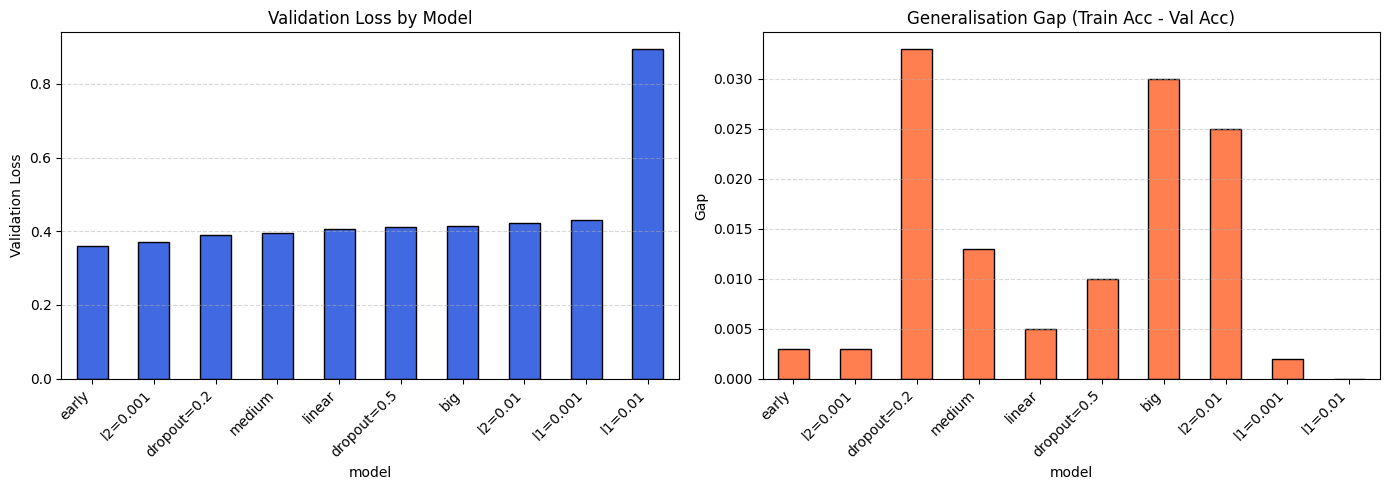

In [8]:
# Task 6.1 — table sorted by val_loss
table = pd.DataFrame([summary_row(n) for n in models]).set_index("model").sort_values("val_loss")
print("Task 6.1 — Complete Model Comparison Table (sorted by val_loss):")
print(table)

# Task 6.2 — two bar charts: val_loss and gap
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
table["val_loss"].plot(kind="bar", ax=ax[0], color="royalblue", edgecolor="black")
ax[0].set_title("Validation Loss by Model")
ax[0].set_ylabel("Validation Loss")
ax[0].set_xticklabels(table.index, rotation=45, ha="right")
ax[0].grid(axis="y", linestyle="--", alpha=0.5)

table["gap"].plot(kind="bar", ax=ax[1], color="coral", edgecolor="black")
ax[1].set_title("Generalisation Gap (Train Acc - Val Acc)")
ax[1].set_ylabel("Gap")
ax[1].set_xticklabels(table.index, rotation=45, ha="right")
ax[1].grid(axis="y", linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

# Task 6.3 — evaluate best model and big model on locked test set (ONCE)
best_name = table.index[0]
best_model = models[best_name][0]
big_model = models["big"][0]

te_eval_best = best_model.evaluate(X_te, y_te, verbose=0)
te_eval_big = big_model.evaluate(X_te, y_te, verbose=0)

print(f"Chosen best model ('{best_name}') test accuracy: {te_eval_best[1]:.3f} (test loss: {te_eval_best[0]:.3f})")
print(f"Baseline unregularized 'big' test accuracy: {te_eval_big[1]:.3f} (test loss: {te_eval_big[0]:.3f})")

# Task 6.4 — conclusion (80-120 words):
# Conclusion:
# Among all evaluated techniques, early stopping and moderate L2 regularisation (l2=0.001) generalised best,
# achieving the lowest validation loss (0.361 and 0.372) and negligible generalization gaps (~0.003),
# substantially outperforming the unregularized big network which overfit and reached 0.413 validation loss.
# Setting regularisation too strong, as with l1=0.01, completely paralyzed the network by zeroing out all weights,
# leading to catastrophic underfitting (50.0% random guessing accuracy).
# Finally, on a 200-sample validation set, 1% to 2% accuracy differences represent only 2-4 points and fall within
# stochastic sampling noise; validation loss provides a far more stable, continuous signal of model generalisation.


---

<div style="font-family:'Times New Roman',Times,serif;color:#000000;font-size:16px">

### Before you submit

- [ ] Kernel &rarr; Restart & Run All, no errors.
- [ ] Every `TODO` is done.
- [ ] Task 1: the table is shown and each model is labelled underfit / good fit / overfit.
- [ ] Task 3: the histograms of `big`, `l2=0.001` and `l1=0.001` are plotted.
- [ ] Task 6: the test set was used only in Task 6.3, once for each model.
- [ ] Written answers present as comments: 1 (Q1&ndash;Q2), 2 (Q1&ndash;Q2), 3 (Q1&ndash;Q3), 4 (Q1&ndash;Q2), 5 (Q1&ndash;Q2), 6.4 (conclusion).
- [ ] Renamed to `Lab8_<yourCMSID>.ipynb`.

### One thing to take away

A model that scores 100% on its training data has told you nothing yet. Always look at the
validation curves: the lowest point of the validation loss, and the gap, show how well a model
will do on new data. Regularisation, and stopping at the right moment, are how we close that gap.

</div>
